<a href="https://colab.research.google.com/github/RaefLaabidi/ING3_AI_DL_project_CY/blob/main/PROJET_ATTIA_LAABIDI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
from google.colab import files
uploded = files.upload()

Saving archive (1).zip to archive (1).zip


In [ ]:
!unzip -q "archive (1).zip"

In [ ]:
import os

print(os.listdir())

['.config', 'test', 'train', 'archive (1).zip', 'sample_data']


In [ ]:
print(os.listdir("train"))

['surprise', 'angry', 'sad', 'disgust', 'fear', 'happy', 'neutral']


In [ ]:
print(os.listdir("test"))

['surprise', 'angry', 'sad', 'disgust', 'fear', 'happy', 'neutral']


In [ ]:
# les 7 classes
classes = ["angry",
           "disgust",
           "fear",
           "happy",
           "sad",
           "surprise",
           "neutral"
           ]

## Partie 1 : Recherche, compréhension et préparation des données

### 1.1 Source du dataset

- **Nom du dataset :** FER2013 (Facial Expression Recognition 2013)
- **Auteurs :** Ian Goodfellow et al. (Université de Montréal), dans le cadre d'un concours de machine learning. Référence : *Challenges in Representation Learning: A report on three machine learning contests* (2013).
- **Lien :** https://www.kaggle.com/c/Facial-Expression-Recognition (version utilisée : https://www.kaggle.com/datasets/msambare/fer2013)
- **Licence d'utilisation :** CC0 1.0 Universal (domaine public). Le dataset peut être copié, modifié et utilisé, y compris à des fins commerciales, sans demander d'autorisation. Lien : https://creativecommons.org/publicdomain/zero/1.0/  Les données proviennent d'un concours Kaggle et nous les utilisons uniquement dans un cadre académique.

### 1.2 Caractéristiques du dataset

| Caractéristique | Valeur |
|---|---|
| Nombre total d'images | 35 887 (28 709 en train, 7 178 en test) |
| Classes | colère, dégoût, peur, joie, tristesse, surprise, neutre (7 classes) |
| Dimensions des images | 48 × 48 pixels |
| Format | niveaux de gris (1 canal) |
| Déséquilibre | oui, la classe « dégoût » est très minoritaire |

*(Les chiffres exacts par classe sont calculés dans la cellule de code ci-dessous.)*

### 1.3 Pourquoi avons-nous choisi FER2013 ?

Après avoir comparé plusieurs datasets d'expressions faciales, nous avons retenu FER2013 pour les raisons suivantes :

1. **Il correspond au sujet :** il contient les 7 expressions demandées (joie, tristesse, colère, surprise, peur, dégoût, neutre).
2. **Il est très utilisé :** il sert de référence dans de nombreux articles de recherche, ce qui nous permet de situer nos résultats par rapport à la littérature. Il est de plus facile à télécharger sur Kaggle.
3. **Il est léger :** des images de 48×48 en niveaux de gris permettent un entraînement rapide sur Google Colab.
4. **Il est réaliste et difficile :** les images viennent du web, avec des variations de lumière, de pose et d'occlusions. Même un humain ne reconnaît pas toujours l'expression correcte, donc une accuracy parfaite n'est pas attendue.
5. **Il est adapté à l'analyse demandée :** le déséquilibre entre classes justifie l'usage de la matrice de confusion (partie 5), et sa difficulté permet de tester des améliorations en partie 6 (Dropout, data augmentation, etc.).
6. **Il est déjà séparé en train et test**, ce qui simplifie la préparation des données. Nous créerons ensuite un ensemble de validation à partir du train.

**Limite à garder en tête :** les labels ont été obtenus par annotation collaborative et peuvent contenir du bruit. Cela explique en partie les confusions entre expressions proches (par exemple peur et surprise).

In [ ]:
# compter les images par classe
for class_name in classes:
  train_path = os.path.join("train", class_name)
  test_path = os.path.join("test", class_name)

  train_count = len(os.listdir(train_path))
  test_count = len(os.listdir(test_path))

  print(class_name, "-> train :", train_count, "| test :", test_count)

angry -> train : 3995 | test : 958
disgust -> train : 436 | test : 111
fear -> train : 4097 | test : 1024
happy -> train : 7215 | test : 1774
sad -> train : 4830 | test : 1247
surprise -> train : 3171 | test : 831
neutral -> train : 4965 | test : 1233


=> il existe un déséquilibre des classes

In [ ]:
# verifier une image

from PIL import Image

image_path = "train/happy/" + os.listdir("train/happy")[0]
image = Image.open(image_path)

print("Taille :", image.size)
print("Mode :", image.mode)

Taille : (48, 48)
Mode : L


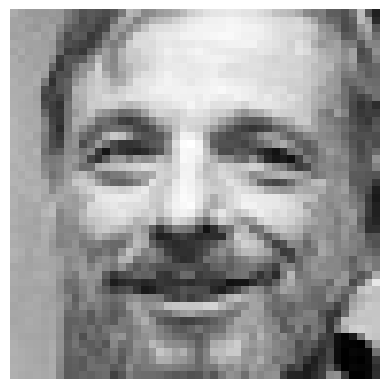

In [ ]:
# Afficher l'image

plt.imshow(image, cmap="gray")
plt.axis("off")
plt.show()

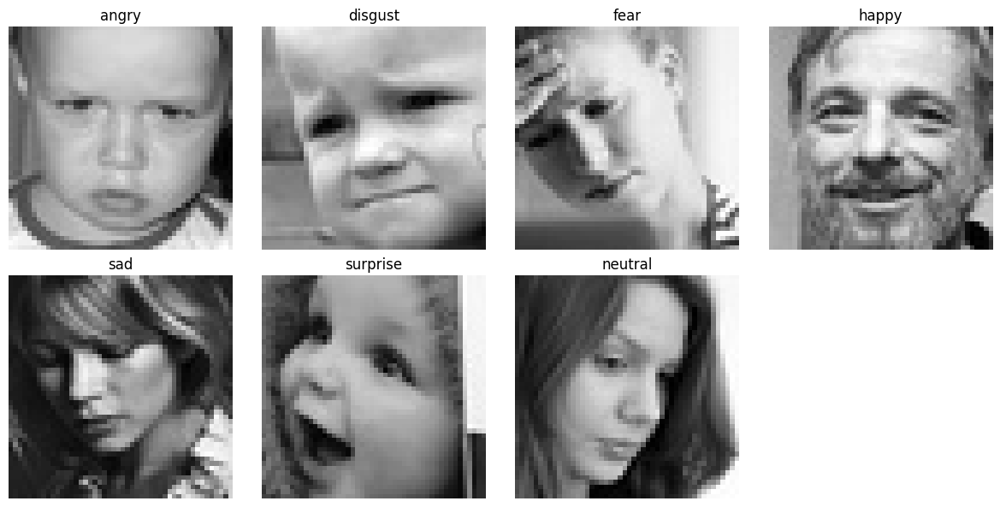

In [ ]:
plt.figure(figsize=(12,6))

for i, class_name in enumerate(classes):
  image_path = "train/" + class_name + "/" + os.listdir("train/" + class_name)[0]
  image = Image.open(image_path)

  plt.subplot(2, 4, i+1)
  plt.imshow(image, cmap="gray")
  plt.title(class_name)
  plt.axis("off")
plt.tight_layout()
plt.show()


In [ ]:
import numpy as np
from PIL import Image
from sklearn.model_selection import train_test_split

Chargement des images et préparation des labels

In [ ]:
X_train = []
y_train = []

X_test = []
y_test = []

for class_index, class_name in enumerate(classes):

    # Images d'entraînement
    train_path = os.path.join("train", class_name)

    for filename in os.listdir(train_path):
        image_path = os.path.join(train_path, filename)

        image = Image.open(image_path).convert("L")
        image = np.array(image)

        X_train.append(image)
        y_train.append(class_index)

    # Images de test
    test_path = os.path.join("test", class_name)

    for filename in os.listdir(test_path):
        image_path = os.path.join(test_path, filename)

        image = Image.open(image_path).convert("L")
        image = np.array(image)

        X_test.append(image)
        y_test.append(class_index)

Conversion en tableaux NumPy

In [ ]:
X_train = np.array(X_train)
y_train = np.array(y_train)

X_test = np.array(X_test)
y_test = np.array(y_test)

print("X_train :", X_train.shape)
print("y_train :", y_train.shape)

print("X_test  :", X_test.shape)
print("y_test  :", y_test.shape)

X_train : (28709, 48, 48)
y_train : (28709,)
X_test  : (7178, 48, 48)
y_test  : (7178,)


Création de l'ensemble de validation

Le dataset fournit déjà un ensemble d'entraînement et un ensemble de test. Nous créons donc l'ensemble de validation à partir de l'ensemble d'entraînement.

In [ ]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("X_train :", X_train.shape)
print("X_val   :", X_val.shape)
print("X_test  :", X_test.shape)

X_train : (22967, 48, 48)
X_val   : (5742, 48, 48)
X_test  : (7178, 48, 48)


L'option stratify=y_train permet de conserver approximativement la même proportion de chaque classe dans les ensembles train et validation.

Le jeu de test n'est pas utilisé lors de cette séparation et reste réservé à l'évaluation finale.

**Normalisation des pixels**

Les valeurs originales des pixels sont comprises entre 0 et 255. Nous les normalisons entre 0 et 1 :


In [ ]:
X_train = X_train.astype("float32") / 255.0
X_val = X_val.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

Vérification :

In [ ]:
print("Minimum :", X_train.min())
print("Maximum :", X_train.max())

Minimum : 0.0
Maximum : 1.0


Les images FER2013 sont en niveaux de gris. Elles sont initialement représentées sous la forme (48,48). Nous ajoutons une dimension de canal avec np.newaxis afin d'obtenir (48,48,1), le format attendu pour une image grayscale par une couche convolutionnelle Conv2D. Cette opération n'ajoute pas d'information, elle explicite simplement la présence d'un seul canal.

In [ ]:
X_train = X_train[..., np.newaxis]
X_val = X_val[..., np.newaxis]
X_test = X_test[..., np.newaxis]

In [ ]:
print("X_train :", X_train.shape)
print("y_train :", y_train.shape)

print("X_val   :", X_val.shape)
print("y_val   :", y_val.shape)

print("X_test  :", X_test.shape)
print("y_test  :", y_test.shape)

X_train : (22967, 48, 48, 1)
y_train : (22967,)
X_val   : (5742, 48, 48, 1)
y_val   : (5742,)
X_test  : (7178, 48, 48, 1)
y_test  : (7178,)


# Partie 2 — Construction d’un modèle de référence


Avant de construire un réseau de neurones convolutif (CNN), nous allons construire un premier réseau de neurones simple.

Ce modèle servira de **modèle de référence (baseline)**. L'objectif n'est pas d'obtenir les meilleures performances possibles, mais d'avoir un premier résultat que nous pourrons ensuite comparer avec celui du CNN.

L'architecture utilisée est :

**Image → Flatten → Dense + ReLU → Dense + Softmax**

Dans cette partie, nous allons comprendre :
- comment transformer une image en entrée du réseau ;
- le rôle des poids et des biais ;
- la propagation avant ;
- les fonctions d'activation ;
- la fonction de perte ;
- la rétropropagation ;
- la descente de gradient ;
- la classification multiclasse.

In [ ]:
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Flatten, Dense

model_dense = Sequential([
    Input(shape=(48, 48, 1)),
    Flatten(),
    Dense(128, activation="relu"),
    Dense(7, activation="softmax")
])

model_dense.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 295,943 (1.13 MB)

 Trainable params: 295,943 (1.13 MB)

 Non-trainable params: 0 (0.00 B)

## 2.1 — Transformation de l'image en entrée du réseau

Les images de FER2013 ont une taille de **48 × 48 pixels** et sont en niveaux de gris.

Chaque image possède donc une seule couche (channel) :

**48 × 48 × 1**

Avant d'entrer dans une couche `Dense`, l'image doit être transformée en un vecteur.

La couche `Flatten` effectue simplement cette transformation :

**(48, 48, 1) → (2304)**

car :

**48 × 48 × 1 = 2304**

Ainsi, les 2304 valeurs correspondent aux pixels de l'image et deviennent les entrées du premier réseau de neurones.

`Flatten` n'apprend aucun paramètre. Elle ne modifie pas les valeurs des pixels : elle change uniquement leur organisation.

## 2.2 — Première couche Dense

Nous utilisons ensuite :

`Dense(128, activation="relu")`

Cette couche contient **128 neurones**.

Chaque neurone reçoit les **2304 valeurs** provenant de l'image.

Pour un neurone, le calcul est de la forme :

**z = w₁x₁ + w₂x₂ + ... + w₂₃₀₄x₂₃₀₄ + b**

où :

- `x` représente les valeurs des pixels ;
- `w` représente les poids ;
- `b` représente le biais ;
- `z` est le résultat avant activation.

### Rôle des poids

Les poids permettent au réseau d'apprendre quelles informations sont importantes pour reconnaître une expression.

Pendant l'entraînement, leurs valeurs sont progressivement modifiées afin de réduire l'erreur du modèle.

### Rôle du biais

Le biais permet de décaler le résultat du neurone.

Il donne au neurone une certaine flexibilité supplémentaire et est également appris pendant l'entraînement.

## 2.3 — Fonction d'activation ReLU

Après le calcul du neurone, nous appliquons la fonction d'activation `ReLU`.

La fonction ReLU est définie par :

**ReLU(x) = max(0, x)**

Cela signifie que :

- si `x < 0`, la sortie est `0` ;
- si `x > 0`, la sortie reste `x`.

La fonction ReLU introduit de la **non-linéarité** dans le réseau.

Sans fonction d'activation, plusieurs couches Dense successives pourraient être équivalentes à une seule transformation linéaire. L'activation permet donc au réseau d'apprendre des relations plus complexes dans les données.

## 2.4 — Couche de sortie

La dernière couche est :

`Dense(7, activation="softmax")`

Nous avons **7 classes** dans notre problème :

1. Angry
2. Disgust
3. Fear
4. Happy
5. Sad
6. Surprise
7. Neutral

Nous avons donc besoin de **7 neurones de sortie**, un pour chaque expression.

La fonction `Softmax` transforme les sorties en probabilités.

Par exemple, le réseau pourrait produire :

- Angry : 0.05
- Disgust : 0.02
- Fear : 0.10
- Happy : 0.70
- Sad : 0.08
- Surprise : 0.03
- Neutral : 0.02

La somme des probabilités est égale à 1.

La classe ayant la probabilité la plus élevée devient la prédiction du modèle.

Dans cet exemple, le modèle prédit donc **Happy**.

## 2.5 — Nombre de paramètres

Il est important de comprendre que le réseau apprend des **paramètres** : les poids et les biais.

Pour la première couche Dense :

- 2304 entrées
- 128 neurones

Chaque neurone possède 2304 poids et 1 biais.

Le nombre de paramètres est donc :

**2304 × 128 + 128 = 295 040**

Pour la couche de sortie :

- 128 entrées
- 7 neurones

Le nombre de paramètres est :

**128 × 7 + 7 = 903**

La couche `Flatten` possède quant à elle **0 paramètre**, car elle ne fait qu'une transformation de forme.

Le réseau possède donc au total :

**295 040 + 903 = 295 943 paramètres entraînables.**

Cela montre déjà une limite de cette approche : même avec des images de seulement 48 × 48 pixels, le passage directement vers une couche Dense produit beaucoup de paramètres.

## 2.6 — Compilation du modèle

Avant l'entraînement, nous devons définir :

- l'optimiseur ;
- la fonction de perte ;
- les métriques utilisées pour suivre les performances.

In [ ]:
model_dense.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

### Fonction de perte

Nous utilisons :

`sparse_categorical_crossentropy`

Notre problème est une **classification multiclasse** avec 7 classes.

Les labels sont stockés sous forme d'entiers :

- `0` → Angry
- `1` → Disgust
- `2` → Fear
- `3` → Happy
- `4` → Sad
- `5` → Surprise
- `6` → Neutral

La fonction de perte compare la probabilité prédite par le réseau avec la vraie classe.

Plus la prédiction est mauvaise, plus la perte est élevée.

L'objectif de l'entraînement sera donc de **minimiser cette perte**.

Nous utilisons `sparse_categorical_crossentropy` car nos labels sont des entiers et non des vecteurs one-hot.

### Optimiseur Adam

Nous utilisons l'optimiseur `Adam`.

Son rôle est de modifier les poids et les biais du réseau afin de réduire progressivement la fonction de perte.

Adam est une méthode d'optimisation basée sur les gradients. Elle adapte notamment la taille des mises à jour pour les différents paramètres.

Nous n'avons donc pas besoin de modifier manuellement chaque poids pendant l'entraînement.

## 2.7 — Propagation avant (Forward Propagation)

Pendant la propagation avant, l'information circule de l'entrée vers la sortie.

Le processus est :

**Image**
↓
**Flatten**
↓
**Dense + ReLU**
↓
**Dense + Softmax**
↓
**7 probabilités**

Pour une image donnée, le réseau calcule donc une prédiction.

Cette prédiction est ensuite comparée au vrai label grâce à la fonction de perte.

## 2.8 — Rétropropagation (Backpropagation)

Après la propagation avant, nous obtenons une valeur de perte.

La rétropropagation permet de déterminer comment chaque poids et chaque biais du réseau a contribué à cette erreur.

Le principe est de calculer les **gradients** de la fonction de perte par rapport aux paramètres du réseau.

On peut donc savoir dans quelle direction modifier les paramètres pour diminuer la perte.

Le processus général est :

**Propagation avant → calcul de la perte → rétropropagation → calcul des gradients → mise à jour des paramètres**

## 2.9 — Descente de gradient

Une fois les gradients calculés, l'optimiseur met à jour les paramètres.

L'idée générale peut être représentée par :

**nouveau paramètre = ancien paramètre − taux d'apprentissage × gradient**

Le gradient indique la direction dans laquelle la perte augmente.

On se déplace donc dans la direction opposée afin de réduire la perte.

Dans notre modèle, ces mises à jour sont réalisées automatiquement par l'optimiseur Adam.

## 2.10 — Entraînement du modèle

Nous allons maintenant entraîner le réseau.

Nous utilisons :

- `epochs=20` : le modèle parcourt au maximum 20 fois les données d'entraînement ;
- `batch_size=64` : les images sont traitées par groupes de 64 ;
- `validation_data` : les performances sont mesurées sur l'ensemble de validation après chaque époque.

L'ensemble de validation n'est pas utilisé pour mettre directement à jour les poids du modèle. Il permet de suivre la capacité du modèle à généraliser sur des données qu'il n'a pas utilisées pour apprendre ses paramètres.

In [ ]:
history_dense = model_dense.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=64
)

Epoch 1/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.2743 - loss: 1.7987 - val_accuracy: 0.2959 - val_loss: 1.7393
Epoch 2/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.3222 - loss: 1.7172 - val_accuracy: 0.3406 - val_loss: 1.6996
Epoch 3/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.3421 - loss: 1.6802 - val_accuracy: 0.3462 - val_loss: 1.6784
Epoch 4/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.3465 - loss: 1.6701 - val_accuracy: 0.3574 - val_loss: 1.6504
Epoch 5/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.3534 - loss: 1.6558 - val_accuracy: 0.3595 - val_loss: 1.6455
Epoch 6/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.3577 - loss: 1.6420 - val_accuracy: 0.3258 - val_loss: 1.7031
Epoch 7/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.3583 - loss: 1.6354 - val_accuracy: 0.3534 - val_loss: 1.6520
Epoch 8/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.3637 - loss: 1.6282 - val_accuracy: 

## 2.11 — Évaluation finale sur le test

Après l'entraînement, nous évaluons le modèle sur l'ensemble de test.

Le test est conservé séparément pendant le développement afin d'obtenir une évaluation finale des performances du modèle sur des données qui n'ont pas servi à l'entraînement.

In [ ]:
test_loss, test_accuracy = model_dense.evaluate(
    X_test,
    y_test
)

print("Test loss :", test_loss)
print("Test accuracy :", test_accuracy)

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3727 - loss: 1.6101
Test loss : 1.6101040840148926
Test accuracy : 0.37266647815704346


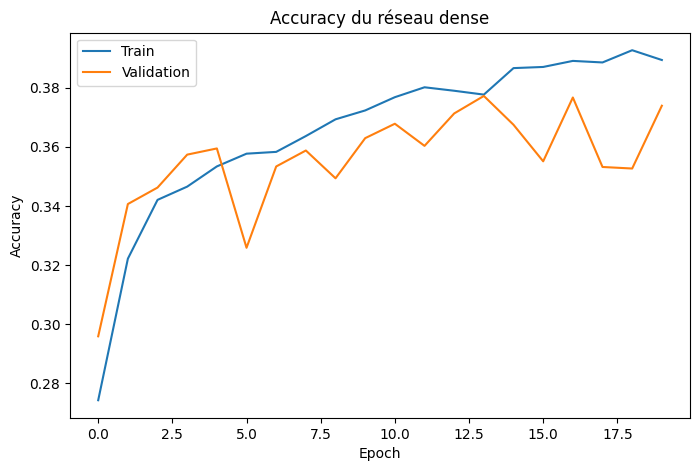

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_dense.history["accuracy"],
    label="Train"
)

plt.plot(
    history_dense.history["val_accuracy"],
    label="Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy du réseau dense")
plt.legend()
plt.show()

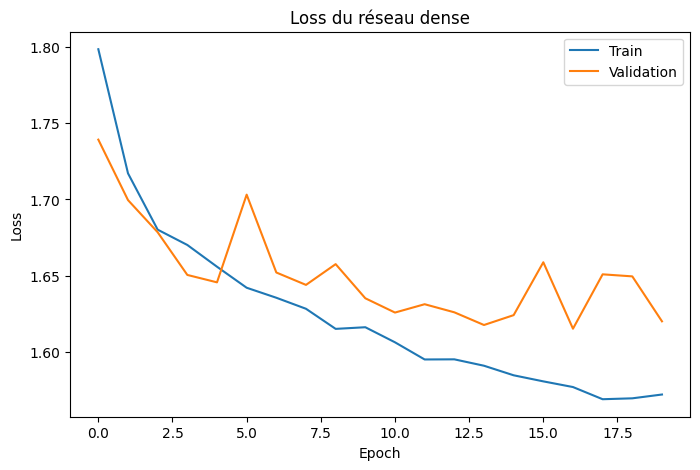

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_dense.history["loss"],
    label="Train"
)

plt.plot(
    history_dense.history["val_loss"],
    label="Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss du réseau dense")
plt.legend()
plt.show()

# Partie 3 — Construction d'un CNN avec Keras

Dans la partie précédente, nous avons construit un réseau de neurones dense servant de modèle de référence.

Nous allons maintenant construire un **réseau de neurones convolutif (CNN)** adapté à la reconnaissance des expressions faciales.

Contrairement au réseau dense, un CNN est particulièrement adapté aux images car il peut exploiter leur structure spatiale.

L'architecture choisie est :

**Image → Conv2D + ReLU → MaxPooling → Conv2D + ReLU → MaxPooling → Flatten → Dense + ReLU → Softmax**

Notre réseau sera composé de deux blocs de convolution et de pooling :

**Bloc 1 :**
- Conv2D avec 32 filtres
- ReLU
- MaxPooling

**Bloc 2 :**
- Conv2D avec 64 filtres
- ReLU
- MaxPooling

Puis :

- Flatten
- Dense de 128 neurones avec ReLU
- Dense de 7 neurones avec Softmax

Cette architecture est volontairement relativement simple. Elle permet d'extraire progressivement des caractéristiques visuelles tout en restant adaptée à des images de petite taille (48 × 48 pixels).

## 3.1 — Pourquoi utiliser un CNN ?

Dans le modèle dense précédent, nous avons utilisé `Flatten` directement sur l'image.

L'image :

**48 × 48 × 1**

était transformée en :

**2304 valeurs**

puis chaque neurone Dense était connecté à tous les pixels.

Cette approche présente une limite importante : elle ne tient pas directement compte de la position des pixels dans l'image.

Un CNN fonctionne différemment.

Il utilise des **filtres (kernels)** qui se déplacent sur l'image afin de détecter des caractéristiques locales.

Par exemple, les premières couches peuvent apprendre à détecter :

- des contours ;
- des lignes ;
- des changements de luminosité ;
- des formes simples.

Les couches suivantes peuvent ensuite combiner ces informations pour apprendre des caractéristiques plus complexes du visage.

On peut donc résumer le rôle du CNN ainsi :

**Image → extraction de caractéristiques → classification**

## 3.2 — Les filtres et la convolution

Une couche `Conv2D` utilise plusieurs **filtres**, aussi appelés **kernels**.

Un filtre est une petite matrice de nombres qui se déplace sur l'image.

À chaque position, le filtre effectue des multiplications avec les valeurs des pixels situés dans sa zone, puis additionne les résultats.

Le résultat obtenu produit une nouvelle représentation de l'image appelée **feature map**.

De manière simplifiée :

**Image + filtre → convolution → feature map**

Pendant l'entraînement, les valeurs des filtres sont apprises automatiquement.

Le réseau apprend donc quels motifs sont utiles pour reconnaître les différentes expressions faciales.

## 3.3 — Kernel, stride et padding

### Kernel

Le **kernel** correspond à la taille du filtre utilisé pour effectuer la convolution.

Nous allons utiliser :

**3 × 3**

Un kernel 3 × 3 observe donc une petite zone de 3 pixels × 3 pixels à chaque position.

Cette taille est très courante pour les CNN car elle permet de détecter des caractéristiques locales tout en gardant un nombre de paramètres raisonnable.

### Stride

Le **stride** correspond au déplacement du filtre à chaque étape.

Avec `stride=1`, le filtre se déplace d'un pixel à la fois.

Nous utiliserons la valeur par défaut :

**stride = 1**

### Padding

Le **padding** consiste à ajouter des pixels autour de l'image avant la convolution.

Nous utiliserons :

**padding="same"**

Avec `stride=1`, cela permet de conserver la hauteur et la largeur de la feature map.

Ainsi :

**48 × 48 → 48 × 48**

après la première convolution.

## 3.4 — Fonction d'activation ReLU

Après chaque convolution, nous appliquons la fonction d'activation `ReLU`.

La fonction est définie par :

**ReLU(x) = max(0, x)**

Elle remplace donc les valeurs négatives par 0 et conserve les valeurs positives.

La ReLU introduit de la **non-linéarité** dans le réseau.

Elle permet au CNN d'apprendre des relations plus complexes entre les caractéristiques extraites de l'image.

## 3.5 — Première couche de convolution

La première couche sera :

`Conv2D(32, kernel_size=(3,3), padding="same", activation="relu")`

Cette couche possède **32 filtres différents**.

Chaque filtre apprend à détecter certains motifs dans l'image.

Comme nous avons une image en niveaux de gris avec une seule couche :

**Entrée : 48 × 48 × 1**

et que nous utilisons 32 filtres, la sortie contient :

**48 × 48 × 32**

Les 32 canaux correspondent aux **32 feature maps** produites par les 32 filtres.

Chaque feature map représente donc la réponse d'un filtre aux différents endroits de l'image.

In [ ]:
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

model_cnn = Sequential([
    Input(shape=(48, 48, 1)),

    Conv2D(
        32,
        kernel_size=(3, 3),
        padding="same",
        activation="relu"
    ),

    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(
        64,
        kernel_size=(3, 3),
        padding="same",
        activation="relu"
    ),

    MaxPooling2D(pool_size=(2, 2)),

    Flatten(),

    Dense(128, activation="relu"),

    Dense(7, activation="softmax")
])

model_cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     1,179,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,199,495 (4.58 MB)

 Trainable params: 1,199,495 (4.58 MB)

 Non-trainable params: 0 (0.00 B)

## 3.6 — Première couche de pooling

Après la première convolution, nous appliquons :

`MaxPooling2D(pool_size=(2,2))`

Le **pooling** permet de réduire les dimensions spatiales des feature maps.

Avec un MaxPooling 2 × 2, chaque zone de 2 × 2 pixels est remplacée par sa valeur maximale.

Par exemple :

**[1  5]**  
**[2  3]**

devient :

**5**

Cela permet :

- de réduire la taille des données ;
- de diminuer le nombre de calculs ;
- de conserver les activations les plus importantes ;
- de rendre les représentations un peu moins sensibles à de petits déplacements.

Avant le pooling :

**48 × 48 × 32**

Après le pooling :

**24 × 24 × 32**

Le nombre de canaux reste 32 : le pooling réduit uniquement la hauteur et la largeur.

## 3.7 — Deuxième couche de convolution

Nous appliquons ensuite une deuxième convolution :

`Conv2D(64, kernel_size=(3,3), padding="same", activation="relu")`

Cette fois, nous utilisons **64 filtres**.

L'entrée possède maintenant :

**24 × 24 × 32**

Les filtres utilisent donc les 32 canaux disponibles en entrée pour construire des caractéristiques plus complexes.

La sortie possède :

**24 × 24 × 64**

Le nombre de feature maps passe donc de 32 à 64.

L'idée est que les premières couches apprennent plutôt des caractéristiques simples, tandis que les couches suivantes peuvent combiner ces caractéristiques pour construire des représentations plus complexes.

## 3.8 — Deuxième couche de pooling

Nous appliquons à nouveau :

`MaxPooling2D(pool_size=(2,2))`

Avant le pooling :

**24 × 24 × 64**

Après le pooling :

**12 × 12 × 64**

Nous avons donc réduit progressivement la taille spatiale tout en conservant les 64 feature maps.

## 3.9 — Flatten

Après les deux blocs convolution + pooling, nous obtenons :

**12 × 12 × 64**

La couche `Flatten` transforme cette représentation en un seul vecteur :

**12 × 12 × 64 = 9216**

Nous obtenons donc :

**12 × 12 × 64 → 9216**

Comme dans le modèle dense précédent, `Flatten` ne possède aucun paramètre entraînable.

Son rôle est simplement de transformer les caractéristiques extraites par le CNN en un vecteur qui pourra être envoyé vers les couches Dense.

## 3.10 — Couche Dense

Après `Flatten`, nous utilisons :

`Dense(128, activation="relu")`

Cette couche contient 128 neurones.

Elle reçoit les **9216 caractéristiques** produites par la partie convolutionnelle du réseau.

Son rôle est de combiner les caractéristiques extraites afin de prendre une décision de classification.

La ReLU est utilisée ici pour introduire de nouveau de la non-linéarité.

## 3.11 — Couche de sortie Softmax

La dernière couche est :

`Dense(7, activation="softmax")`

Nous avons 7 expressions faciales, donc nous avons besoin de 7 neurones de sortie.

La fonction Softmax transforme les sorties en probabilités.

Les 7 probabilités correspondent respectivement à :

1. Angry
2. Disgust
3. Fear
4. Happy
5. Sad
6. Surprise
7. Neutral

La classe ayant la probabilité la plus élevée correspond à la prédiction du réseau.

## 3.12 — Évolution des dimensions dans le CNN

Nous pouvons maintenant suivre l'évolution de la représentation de l'image dans tout le réseau.

| Couche | Sortie | Explication |
|---|---:|---|
| Entrée | 48 × 48 × 1 | Image en niveaux de gris |
| Conv2D 32 filtres | 48 × 48 × 32 | Extraction de 32 types de caractéristiques |
| MaxPooling 2×2 | 24 × 24 × 32 | Réduction spatiale |
| Conv2D 64 filtres | 24 × 24 × 64 | Extraction de caractéristiques plus complexes |
| MaxPooling 2×2 | 12 × 12 × 64 | Nouvelle réduction spatiale |
| Flatten | 9216 | Transformation en vecteur |
| Dense 128 | 128 | Combinaison des caractéristiques |
| Dense 7 + Softmax | 7 | Probabilités des 7 expressions |

On observe donc que :

- la hauteur et la largeur diminuent progressivement ;
- le nombre de feature maps augmente ;
- les représentations deviennent progressivement plus abstraites ;
- la partie convolutionnelle extrait les caractéristiques ;
- la partie Dense réalise la classification finale.

## 3.13 — Nombre de paramètres

Il est important de connaître le nombre de paramètres car ce sont les valeurs que le réseau va apprendre pendant l'entraînement.

### Première convolution

La première couche possède :

- kernel : 3 × 3
- 1 canal d'entrée
- 32 filtres

Nombre de paramètres :

**(3 × 3 × 1 × 32) + 32 = 320**

Les 32 paramètres supplémentaires correspondent aux 32 biais, un par filtre.

### Premier MaxPooling

Le MaxPooling ne contient aucun paramètre entraînable.

Donc :

**0 paramètre**

### Deuxième convolution

La deuxième convolution reçoit 32 canaux et possède 64 filtres.

Nombre de paramètres :

**(3 × 3 × 32 × 64) + 64 = 18 496**

### Deuxième MaxPooling

Le MaxPooling ne possède aucun paramètre :

**0 paramètre**

### Flatten

Flatten ne possède aucun paramètre :

**0 paramètre**

### Dense 128

La couche Dense reçoit 9216 valeurs et possède 128 neurones.

Nombre de paramètres :

**9216 × 128 + 128 = 1 179 776**

### Dense 7

La couche finale reçoit 128 valeurs et possède 7 neurones.

Nombre de paramètres :

**128 × 7 + 7 = 903**

Le réseau possède donc environ :

**1 199 495 paramètres entraînables.**

La majorité des paramètres se trouve dans la couche `Dense(128)` après `Flatten`.

## 3.14 — Pourquoi cette architecture ?

Nous avons choisi cette architecture pour plusieurs raisons.

Premièrement, les images sont petites (**48 × 48 pixels**), donc un réseau très profond n'est pas nécessaire pour obtenir une première architecture CNN raisonnable.

Deuxièmement, deux blocs convolution + pooling permettent déjà d'effectuer une extraction hiérarchique des caractéristiques :

**caractéristiques simples → caractéristiques plus complexes → classification**

Troisièmement, nous augmentons le nombre de filtres de **32 à 64**.

La première convolution extrait des caractéristiques relativement simples. La deuxième peut ensuite combiner ces caractéristiques pour apprendre des représentations plus complexes.

Enfin, nous utilisons `3 × 3` comme taille de kernel car elle permet d'observer des zones locales de l'image avec un nombre de paramètres raisonnable.

Cette architecture constitue donc un bon compromis entre simplicité, capacité d'apprentissage et coût de calcul.

# Partie 4 — Entraînement du réseau

Dans cette partie, nous allons entraîner le CNN construit précédemment sur le jeu de données FER2013.

L'objectif est d'apprendre les paramètres du réseau, c'est-à-dire les poids et les biais des différentes couches, afin que le modèle puisse reconnaître correctement les différentes expressions faciales.

Nous allons notamment justifier :

- la fonction de perte ;
- l'optimiseur ;
- le `batch size` ;
- le nombre d'époques ;
- les métriques utilisées.

Nous étudierons ensuite l'évolution de :

- la `loss` d'entraînement et de validation ;
- l'`accuracy` d'entraînement et de validation.

Ces courbes nous permettront notamment de détecter un éventuel **surapprentissage (overfitting)**.

## 4.1 — Fonction de perte

Pour notre problème, nous avons 7 classes d'expressions faciales.

Les labels sont représentés par des entiers :

- `0` → Angry
- `1` → Disgust
- `2` → Fear
- `3` → Happy
- `4` → Sad
- `5` → Surprise
- `6` → Neutral

La sortie de notre CNN utilise une fonction `Softmax` qui produit une probabilité pour chacune des 7 classes.

Nous utilisons donc :

`sparse_categorical_crossentropy`

Cette fonction de perte est adaptée à une classification multiclasse lorsque les labels sont des entiers.

Elle compare les probabilités produites par le modèle avec la vraie classe.

L'objectif de l'entraînement est de **minimiser cette loss**.

Plus la prédiction du modèle est correcte et confiante, plus la loss est faible.

## 4.2 — Optimiseur

Nous utilisons l'optimiseur **Adam**.

L'optimiseur a pour rôle de mettre à jour les poids et les biais du réseau après le calcul des gradients.

Le processus général est :

**Propagation avant**
→ calcul de la prédiction

**Calcul de la loss**
→ mesure de l'erreur

**Rétropropagation**
→ calcul des gradients

**Optimiseur**
→ mise à jour des paramètres

Nous choisissons Adam car il permet d'effectuer automatiquement ces mises à jour de manière adaptative et constitue un choix courant pour l'entraînement des réseaux de neurones.

Le taux d'apprentissage est laissé à sa valeur par défaut pour cette première expérience. Il pourra être modifié plus tard dans les expérimentations de la Partie 6.

## 4.3 — Batch size

Nous choisissons :

**batch_size = 64**

Le `batch size` correspond au nombre d'images utilisées avant d'effectuer une mise à jour des paramètres du réseau.

Avec `batch_size=64`, le modèle :

1. prend 64 images ;
2. effectue une propagation avant ;
3. calcule la loss ;
4. calcule les gradients par rétropropagation ;
5. met à jour les poids ;
6. recommence avec le batch suivant.

Un batch de 64 constitue ici un compromis raisonnable entre stabilité des mises à jour et coût mémoire.

Un batch plus petit pourrait produire des mises à jour plus bruitées, tandis qu'un batch beaucoup plus grand demanderait davantage de mémoire.

## 4.4 — Nombre d'époques

Nous choisissons initialement :

**epochs = 20**

Une époque correspond à un passage complet sur l'ensemble des données d'entraînement.

Le modèle va donc parcourir plusieurs fois les images d'entraînement afin d'améliorer progressivement ses paramètres.

Le choix de 20 époques permet d'observer suffisamment l'évolution du modèle sans entraîner inutilement le réseau pendant un très grand nombre d'époques.

Cependant, le nombre d'époques n'est pas nécessairement optimal.

Les courbes d'entraînement et de validation nous permettront justement de déterminer si le modèle commence à surapprendre.

## 4.5 — Métriques utilisées

Nous utilisons principalement deux mesures :

### Loss

La `loss` mesure l'erreur entre les prédictions du modèle et les vraies classes.

Pendant l'entraînement, nous cherchons généralement à faire diminuer cette valeur.

### Accuracy

L'`accuracy` correspond à la proportion d'images correctement classées.

Par exemple, une accuracy de 80 % signifie que le modèle classe correctement environ 80 images sur 100.

Nous suivrons ces deux mesures sur :

- les données d'entraînement ;
- les données de validation.

La comparaison entre les deux permet de suivre les performances du modèle et de détecter un éventuel surapprentissage.

In [ ]:
model_cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
history_cnn = model_cnn.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=64
)

Epoch 1/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 77s 211ms/step - accuracy: 0.3599 - loss: 1.6440 - val_accuracy: 0.4147 - val_loss: 1.5216
Epoch 2/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 81s 209ms/step - accuracy: 0.4457 - loss: 1.4518 - val_accuracy: 0.4601 - val_loss: 1.4125
Epoch 3/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 82s 208ms/step - accuracy: 0.4929 - loss: 1.3381 - val_accuracy: 0.4835 - val_loss: 1.3674
Epoch 4/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 76s 211ms/step - accuracy: 0.5335 - loss: 1.2394 - val_accuracy: 0.4885 - val_loss: 1.3471
Epoch 5/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 81s 207ms/step - accuracy: 0.5689 - loss: 1.1493 - val_accuracy: 0.5005 - val_loss: 1.3221
Epoch 6/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 75s 209ms/step - accuracy: 0.6094 - loss: 1.0530 - val_accuracy: 0.5024 - val_loss: 1.3319
Epoch 7/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 83s 211ms/step - accuracy: 0.6506 - loss: 0.9471 - val_accuracy: 0.5051 - val_loss: 1.3862
Epoch 8/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 80s 223ms/step - accuracy: 0.6923 - loss: 0

## 4.7 — Évaluation finale sur le jeu de test

Après l'entraînement, nous évaluons le CNN sur le jeu de test.

Le jeu de test n'a pas été utilisé pour apprendre les paramètres du modèle et n'a pas été utilisé comme jeu de validation pendant l'entraînement.

Il permet donc d'obtenir une mesure finale des performances du modèle sur des données conservées à part.

In [ ]:
test_loss_cnn, test_accuracy_cnn = model_cnn.evaluate(
    X_test,
    y_test
)

print("Test loss :", test_loss_cnn)
print("Test accuracy :", test_accuracy_cnn)

225/225 ━━━━━━━━━━━━━━━━━━━━ 7s 31ms/step - accuracy: 0.5029 - loss: 3.5426
Test loss : 3.542612314224243
Test accuracy : 0.5029256343841553


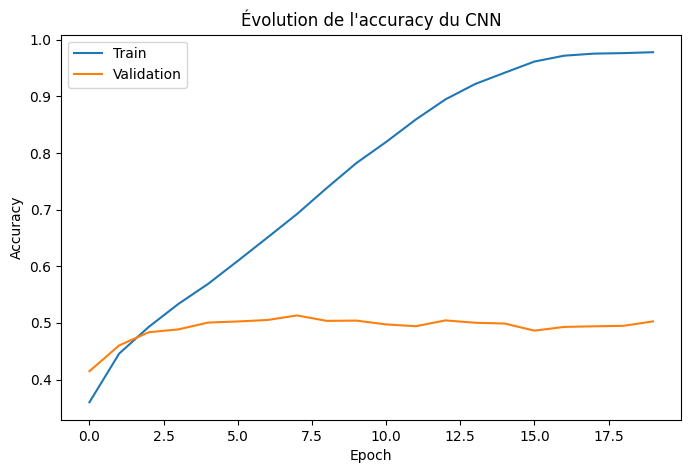

In [32]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_cnn.history["accuracy"],
    label="Train"
)

plt.plot(
    history_cnn.history["val_accuracy"],
    label="Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Évolution de l'accuracy du CNN")
plt.legend()
plt.show()

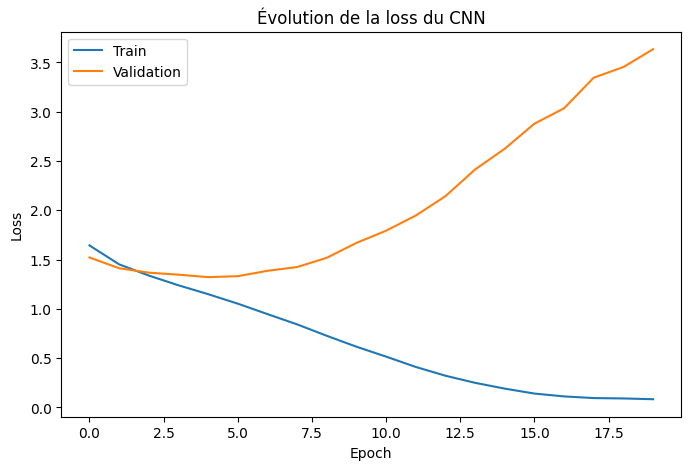

In [33]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_cnn.history["loss"],
    label="Train"
)

plt.plot(
    history_cnn.history["val_loss"],
    label="Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Évolution de la loss du CNN")
plt.legend()
plt.show()

### Lecture des courbes d'apprentissage

Les courbes montrent une amélioration importante de l'accuracy d'entraînement, qui passe d'environ **36 % à 98 %** au cours des 20 époques. En revanche, l'accuracy de validation progresse seulement jusqu'à environ **51 %**, puis reste relativement stable autour de 50 %.

On observe donc un **surapprentissage (overfitting)** à partir d'environ la 5ᵉ–6ᵉ époque : le modèle continue à très bien apprendre les images d'entraînement, mais ses performances sur les données de validation n'augmentent plus. Cela est également visible avec la **validation loss**, qui commence à augmenter alors que la loss d'entraînement continue de diminuer.

Le meilleur résultat de validation est obtenu autour de la **8ᵉ époque**, avec une validation accuracy d'environ **51,3 %**. Ces résultats montrent que le CNN apprend efficacement, mais qu'il commence ensuite à mémoriser les données d'entraînement plutôt qu'à généraliser à de nouvelles images.

### Lecture de la courbe de loss

La loss d'entraînement diminue progressivement tout au long des époques, passant d'environ **1,64 à 0,08**. Cela montre que le modèle apprend de mieux en mieux à prédire les images du jeu d'entraînement.

En revanche, la **validation loss** diminue au début, puis commence à augmenter à partir d'environ la **5ᵉ–6ᵉ époque**. Elle passe d'environ **1,32 à l'époque 5** à **3,63 à l'époque 20**.

Cette divergence entre la loss d'entraînement et la loss de validation est un signe clair de **surapprentissage (overfitting)**. Le modèle devient de plus en plus performant sur les données d'entraînement, mais sa capacité à généraliser à des images qu'il n'a pas vues se dégrade.

Le modèle semble donc commencer à **mémoriser les données d'entraînement** plutôt qu'à apprendre des caractéristiques suffisamment générales pour reconnaître les expressions faciales.

### Partie 5 — Évaluation et analyse des erreurs

L'accuracy globale ne permet pas d'identifier les performances pour chaque expression. Nous utilisons donc une **matrice de confusion** et les métriques par classe afin d'identifier les expressions bien reconnues, les expressions fréquemment confondues et les classes les plus difficiles.

Nous analyserons également quelques prédictions correctes et incorrectes en affichant l'image, la vraie classe, la classe prédite et la probabilité associée.

In [34]:
import numpy as np

# Probabilités prédites pour chaque classe
y_pred_proba = model_cnn.predict(X_test)

# Classe ayant la plus grande probabilité
y_pred = np.argmax(y_pred_proba, axis=1)

print("Nombre de prédictions :", len(y_pred))

225/225 ━━━━━━━━━━━━━━━━━━━━ 7s 30ms/step
Nombre de prédictions : 7178


<Figure size 800x800 with 0 Axes>

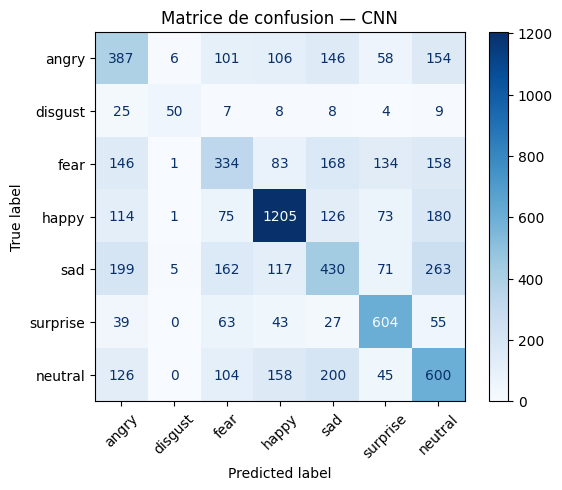

In [35]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 8))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)
disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("Matrice de confusion — CNN")
plt.show()

In [36]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=classes
))

              precision    recall  f1-score   support

       angry       0.37      0.40      0.39       958
     disgust       0.79      0.45      0.57       111
        fear       0.39      0.33      0.36      1024
       happy       0.70      0.68      0.69      1774
         sad       0.39      0.34      0.37      1247
    surprise       0.61      0.73      0.66       831
     neutral       0.42      0.49      0.45      1233

    accuracy                           0.50      7178
   macro avg       0.53      0.49      0.50      7178
weighted avg       0.50      0.50      0.50      7178



### Analyse des résultats

Le CNN obtient une accuracy globale de **50 %** sur le jeu de test. Les performances varient cependant fortement selon les expressions.

L'expression **happy** est bien reconnue, avec un recall de **68 %**, tandis que **surprise** obtient le meilleur recall avec **73 %**. À l'inverse, **fear** (33 %), **sad** (34 %) et **angry** (40 %) sont plus difficiles à reconnaître.

La matrice de confusion montre notamment des confusions entre des expressions visuellement proches, comme **fear et sad**, ainsi qu'entre **angry, fear et neutral**. Le déséquilibre des classes peut également influencer les performances, notamment pour la classe **disgust**, qui possède beaucoup moins d'images que les autres classes.

L'accuracy globale de 50 % masque donc des différences importantes entre les classes, ce qui justifie l'utilisation des métriques par classe et de la matrice de confusion.

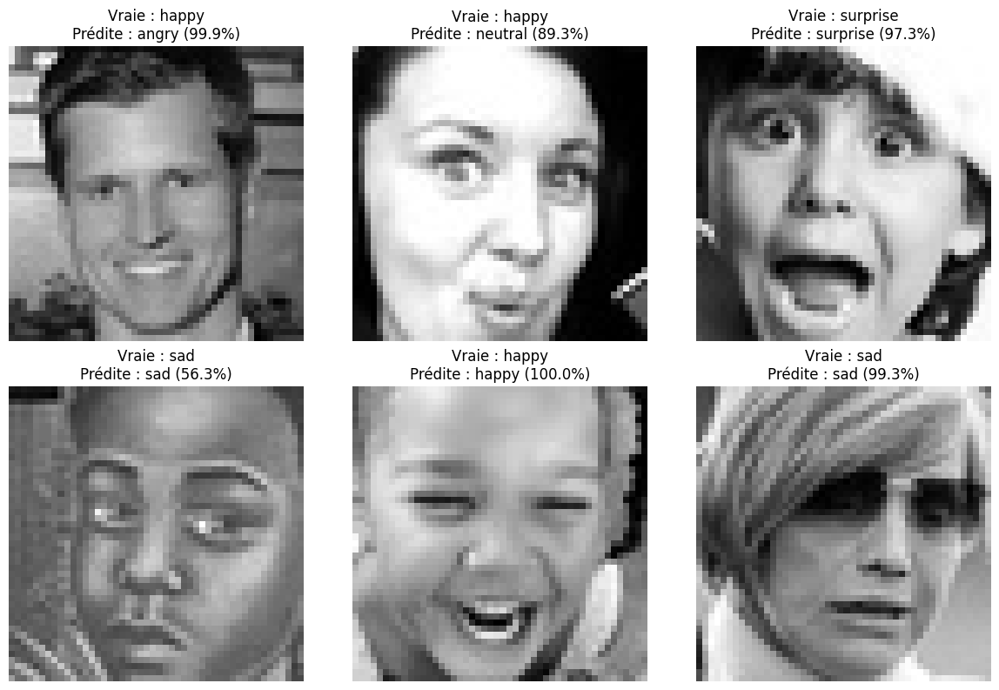

In [37]:
import random
import matplotlib.pyplot as plt

# 6 exemples aléatoires
indices = random.sample(range(len(X_test)), 6)

plt.figure(figsize=(12, 8))

for i, idx in enumerate(indices):
    plt.subplot(2, 3, i + 1)

    plt.imshow(X_test[idx].squeeze(), cmap="gray")

    true_class = classes[y_test[idx]]
    predicted_class = classes[y_pred[idx]]
    probability = y_pred_proba[idx][y_pred[idx]]

    plt.title(
        f"Vraie : {true_class}\n"
        f"Prédite : {predicted_class} ({probability:.1%})"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

## Expérience 1 — Ajout de Dropout

Dans cette expérience, nous conservons la même architecture CNN que précédemment et nous ajoutons une couche de **Dropout** avant la couche dense.

Le Dropout désactive aléatoirement une partie des neurones pendant l'entraînement. Cela empêche le modèle de devenir trop dépendant de certains neurones et peut ainsi réduire le **surapprentissage (overfitting)**.

Cette expérience est motivée par les résultats précédents : notre CNN atteint une très bonne accuracy sur les données d'entraînement, mais l'accuracy de validation reste autour de 50 %. Nous cherchons donc à améliorer la généralisation du modèle.

Nous modifions uniquement l'ajout du Dropout afin de pouvoir comparer son effet avec le modèle de référence.

In [38]:
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

model_cnn_dropout = Sequential([
    Input(shape=(48, 48, 1)),

    Conv2D(32, (3, 3), padding="same", activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), padding="same", activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation="relu"),
    Dropout(0.5),

    Dense(7, activation="softmax")
])

model_cnn_dropout.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     1,179,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,199,495 (4.58 MB)

 Trainable params: 1,199,495 (4.58 MB)

 Non-trainable params: 0 (0.00 B)

In [39]:
model_cnn_dropout.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [40]:
history_dropout = model_cnn_dropout.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=64
)

Epoch 1/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 77s 211ms/step - accuracy: 0.3166 - loss: 1.7139 - val_accuracy: 0.4049 - val_loss: 1.5632
Epoch 2/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 75s 209ms/step - accuracy: 0.3982 - loss: 1.5464 - val_accuracy: 0.4330 - val_loss: 1.4732
Epoch 3/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 76s 213ms/step - accuracy: 0.4393 - loss: 1.4597 - val_accuracy: 0.4626 - val_loss: 1.4000
Epoch 4/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 82s 211ms/step - accuracy: 0.4654 - loss: 1.3902 - val_accuracy: 0.4721 - val_loss: 1.3786
Epoch 5/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 80s 205ms/step - accuracy: 0.4839 - loss: 1.3411 - val_accuracy: 0.4916 - val_loss: 1.3357
Epoch 6/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 76s 211ms/step - accuracy: 0.5068 - loss: 1.2958 - val_accuracy: 0.4960 - val_loss: 1.3129
Epoch 7/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 74s 207ms/step - accuracy: 0.5244 - loss: 1.2493 - val_accuracy: 0.5104 - val_loss: 1.2842
Epoch 8/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 74s 206ms/step - accuracy: 0.5446 - loss: 1

La diminution de l'accuracy d'entraînement n'est pas négative dans ce cas. Elle montre que le Dropout limite la mémorisation des données d'entraînement. En même temps, l'accuracy de validation augmente légèrement, ce qui indique une meilleure généralisation

## Expérience 2 — Data Augmentation

Dans cette expérience, nous ajoutons de la **data augmentation** pendant l'entraînement.

L'objectif est de créer des variations des images d'entraînement, par exemple avec de petites rotations, translations ou variations de zoom. Le modèle est ainsi exposé à davantage de variations possibles des visages.

Cette technique peut améliorer la généralisation et réduire le risque de surapprentissage.

Nous conservons l'architecture CNN et modifions principalement la manière dont les images d'entraînement sont présentées au modèle.

In [41]:
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, Flatten, Dense,
    RandomFlip, RandomRotation, RandomZoom
)

data_augmentation = Sequential([
    RandomFlip("horizontal"),
    RandomRotation(0.1),
    RandomZoom(0.1)
])

In [42]:
model_cnn_aug = Sequential([
    Input(shape=(48, 48, 1)),

    data_augmentation,

    Conv2D(32, (3, 3), padding="same", activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), padding="same", activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation="relu"),

    Dense(7, activation="softmax")
])

model_cnn_aug.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_3 (Sequential)       │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │     1,179,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,199,495 (4.58 MB)

 Trainable params: 1,199,495 (4.58 MB)

 Non-trainable params: 0 (0.00 B)

In [43]:
model_cnn_aug.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [44]:
history_aug = model_cnn_aug.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=64
)

Epoch 1/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 83s 225ms/step - accuracy: 0.2886 - loss: 1.7561 - val_accuracy: 0.3530 - val_loss: 1.6488
Epoch 2/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 80s 219ms/step - accuracy: 0.3575 - loss: 1.6393 - val_accuracy: 0.4117 - val_loss: 1.5427
Epoch 3/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 87s 234ms/step - accuracy: 0.4046 - loss: 1.5506 - val_accuracy: 0.4359 - val_loss: 1.4801
Epoch 4/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 79s 221ms/step - accuracy: 0.4277 - loss: 1.4890 - val_accuracy: 0.4483 - val_loss: 1.4210
Epoch 5/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 79s 220ms/step - accuracy: 0.4464 - loss: 1.4465 - val_accuracy: 0.4669 - val_loss: 1.3882
Epoch 6/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 80s 223ms/step - accuracy: 0.4611 - loss: 1.4121 - val_accuracy: 0.4788 - val_loss: 1.3649
Epoch 7/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 82s 223ms/step - accuracy: 0.4689 - loss: 1.3809 - val_accuracy: 0.4843 - val_loss: 1.3563
Epoch 8/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 81s 221ms/step - accuracy: 0.4762 - loss: 1

### Conclusion de l'expérience 2 — Data Augmentation

La **data augmentation** consiste à appliquer aléatoirement de petites transformations aux images d'entraînement, ici une **rotation**, un **zoom** et un **retournement horizontal**.

L'objectif principal est d'éviter que le modèle mémorise les images d'entraînement et de l'aider à apprendre des caractéristiques plus générales.

Avec cette modification, l'accuracy d'entraînement atteint environ **54,61 %**, tandis que l'accuracy de validation atteint **53,29 %** à la 20ᵉ époque.

Par rapport au CNN de référence, l'amélioration de l'accuracy de validation reste modérée, mais l'écart entre l'entraînement et la validation est fortement réduit. Le modèle présente donc **beaucoup moins de surapprentissage**.

La data augmentation semble ainsi améliorer principalement la **généralisation** du modèle plutôt que sa capacité à mémoriser les données d'entraînement.

**Résultat :** le meilleur score de validation obtenu jusqu'ici est de **53,29 %** avec la data augmentation.

## Expérience 3 — Early Stopping

Dans cette troisième expérience, nous conservons la même architecture CNN que le modèle de référence et nous ajoutons uniquement un mécanisme d'**Early Stopping**.

L'objectif est de limiter le **surapprentissage** en arrêtant automatiquement l'entraînement lorsque la performance sur les données de validation n'améliore plus.

Nous surveillons ici la **validation loss** (`val_loss`). Si celle-ci ne s'améliore pas pendant plusieurs époques consécutives, l'entraînement est arrêté.

Cette expérience permet donc d'étudier l'effet de l'**Early Stopping seul**, sans modifier l'architecture du CNN ni ajouter de Dropout ou de Data Augmentation.

In [47]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [48]:
model_cnn_early = Sequential([
    Input(shape=(48, 48, 1)),
    Conv2D(32, (3, 3), padding="same", activation="relu"),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), padding="same", activation="relu"),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation="relu"),
    Dense(7, activation="softmax")
])

In [49]:
model_cnn_early.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_early = model_cnn_early.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=64,
    callbacks=[early_stopping]
)

Epoch 1/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 78s 213ms/step - accuracy: 0.3573 - loss: 1.6393 - val_accuracy: 0.4020 - val_loss: 1.5280
Epoch 2/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 82s 212ms/step - accuracy: 0.4547 - loss: 1.4355 - val_accuracy: 0.4645 - val_loss: 1.4047
Epoch 3/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 75s 209ms/step - accuracy: 0.4981 - loss: 1.3179 - val_accuracy: 0.4763 - val_loss: 1.3661
Epoch 4/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 88s 227ms/step - accuracy: 0.5340 - loss: 1.2284 - val_accuracy: 0.4972 - val_loss: 1.3340
Epoch 5/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 77s 214ms/step - accuracy: 0.5698 - loss: 1.1423 - val_accuracy: 0.4958 - val_loss: 1.3403
Epoch 6/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 76s 213ms/step - accuracy: 0.6091 - loss: 1.0473 - val_accuracy: 0.5160 - val_loss: 1.3209
Epoch 7/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 75s 209ms/step - accuracy: 0.6525 - loss: 0.9471 - val_accuracy: 0.5228 - val_loss: 1.3639
Epoch 8/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 76s 212ms/step - accuracy: 0.6885 - loss: 0

In [50]:
print("Epochs actually trained:", len(history_early.history["loss"]))

print("Best validation loss:",
      min(history_early.history["val_loss"]))

print("Best validation accuracy:",
      max(history_early.history["val_accuracy"]))

Epochs actually trained: 9
Best validation loss: 1.3208695650100708
Best validation accuracy: 0.5228143334388733


### Conclusion de l'expérience 3 — Early Stopping

L'ajout de l'**Early Stopping** permet de limiter le surapprentissage en arrêtant automatiquement l'entraînement lorsque la validation loss ne s'améliore plus.

L'entraînement s'est arrêté après **9 époques**, au lieu des 20 époques initialement prévues. La meilleure validation loss obtenue est de **1,321**, à l'époque 6, tandis que la meilleure validation accuracy atteint **52,28 %**.

Après l'époque 6, la validation loss commence à augmenter alors que l'accuracy d'entraînement continue de progresser. Cela indique que le modèle commence à se spécialiser sur les données d'entraînement.

Grâce à l'Early Stopping, l'entraînement est donc interrompu avant que le surapprentissage ne devienne plus important. Cette technique permet ainsi de contrôler la durée d'entraînement et d'améliorer la généralisation du modèle.

## Expérience 4 — Augmentation du nombre de couches convolutionnelles

Dans cette expérience, nous modifions uniquement l'**architecture du CNN** en ajoutant une troisième couche convolutionnelle.

Le modèle de référence contient deux blocs convolutionnels avec respectivement **32 et 64 filtres**. Nous ajoutons ici un troisième bloc avec **128 filtres**.

L'objectif est de déterminer si une architecture plus profonde permet au modèle d'apprendre des caractéristiques plus complexes des expressions faciales et d'améliorer ses performances sur les données de validation.

Afin de comparer correctement cette expérience avec les précédentes, nous n'utilisons ni Dropout, ni Data Augmentation, ni Early Stopping.

In [51]:
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

model_cnn_deeper = Sequential([
    Input(shape=(48, 48, 1)),

    # Bloc convolutionnel 1
    Conv2D(32, (3, 3), padding="same", activation="relu"),
    MaxPooling2D((2, 2)),

    # Bloc convolutionnel 2
    Conv2D(64, (3, 3), padding="same", activation="relu"),
    MaxPooling2D((2, 2)),

    # Nouveau bloc convolutionnel
    Conv2D(128, (3, 3), padding="same", activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation="relu"),
    Dense(7, activation="softmax")
])

model_cnn_deeper.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 683,527 (2.61 MB)

 Trainable params: 683,527 (2.61 MB)

 Non-trainable params: 0 (0.00 B)

In [52]:
model_cnn_deeper.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [53]:
history_deeper = model_cnn_deeper.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=64
)

Epoch 1/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 119s 312ms/step - accuracy: 0.3441 - loss: 1.6540 - val_accuracy: 0.4387 - val_loss: 1.4832
Epoch 2/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 113s 315ms/step - accuracy: 0.4774 - loss: 1.3783 - val_accuracy: 0.4934 - val_loss: 1.3237
Epoch 3/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 137s 302ms/step - accuracy: 0.5329 - loss: 1.2455 - val_accuracy: 0.5225 - val_loss: 1.2579
Epoch 4/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 109s 304ms/step - accuracy: 0.5721 - loss: 1.1452 - val_accuracy: 0.5354 - val_loss: 1.2355
Epoch 5/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 142s 303ms/step - accuracy: 0.6102 - loss: 1.0520 - val_accuracy: 0.5510 - val_loss: 1.2048
Epoch 6/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 112s 312ms/step - accuracy: 0.6429 - loss: 0.9621 - val_accuracy: 0.5453 - val_loss: 1.2273
Epoch 7/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 139s 305ms/step - accuracy: 0.6793 - loss: 0.8690 - val_accuracy: 0.5622 - val_loss: 1.3002
Epoch 8/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 145s 315ms/step - accuracy: 0.7135 -

## Comparaison des expériences

Les différentes expériences ont été réalisées à partir du même CNN de référence. Pour chaque expérience, une modification principale a été introduite afin de pouvoir analyser son impact sur les performances et le surapprentissage.

| Modèle | Modification apportée | Meilleure accuracy validation | Observation |
|---|---|---:|---|
| CNN de référence | Aucune modification | **51,31 %** | Performances correctes mais fort surapprentissage |
| Expérience 1 | Dropout (0,5) | **52,68 %** | Réduit fortement le surapprentissage et améliore légèrement la validation |
| Expérience 2 | Data Augmentation | **53,29 %** | Meilleure généralisation et faible écart entre entraînement et validation |
| Expérience 3 | Early Stopping | **52,28 %** | Arrête l'entraînement avant que le surapprentissage devienne trop important |
| Expérience 4 | Ajout d'un 3ᵉ bloc convolutionnel | **56,22 %** | Meilleure accuracy de validation, mais surapprentissage important |

### Analyse

L'ajout d'un troisième bloc convolutionnel donne la meilleure accuracy de validation avec **56,22 %**, contre **51,31 %** pour le CNN de référence. Cette augmentation montre qu'une architecture plus profonde permet au réseau d'apprendre des caractéristiques plus complexes des expressions faciales.

Cependant, cette architecture présente également un surapprentissage important : l'accuracy d'entraînement atteint environ **97 %**, alors que l'accuracy de validation reste autour de **54–56 %**.

La **Data Augmentation** donne une accuracy légèrement inférieure (**53,29 %**), mais avec un écart beaucoup plus faible entre l'entraînement et la validation. Elle améliore donc principalement la capacité de généralisation.

Le **Dropout** réduit également le surapprentissage, tandis que l'**Early Stopping** permet d'arrêter automatiquement l'entraînement lorsque la validation loss ne s'améliore plus.

Ainsi, les résultats montrent qu'il existe un compromis entre **capacité du modèle** et **généralisation**. Le modèle plus profond obtient les meilleures performances de validation, mais il nécessite des techniques de régularisation pour limiter son surapprentissage.

Expérience 5 — CNN régularisé avec Batch Normalization, Dropout et Global Average Pooling

In [60]:
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    BatchNormalization,
    Dropout,
    GlobalAveragePooling2D,
    Dense,
    RandomFlip,
    RandomRotation,
    RandomZoom
)
from tensorflow.keras.callbacks import EarlyStopping


# =========================
# Data augmentation
# =========================

data_augmentation_pro = Sequential([
    RandomFlip("horizontal"),
    RandomRotation(0.1),
    RandomZoom(0.1)
])


# =========================
# Professional CNN
# =========================

model_pro = Sequential([

    Input(shape=(48, 48, 1)),

    data_augmentation_pro,

    # ----- Block 1 -----
    Conv2D(32, (3, 3), padding="same", activation="relu"),
    BatchNormalization(),

    Conv2D(32, (3, 3), padding="same", activation="relu"),
    BatchNormalization(),

    MaxPooling2D((2, 2)),
    Dropout(0.25),

    # ----- Block 2 -----
    Conv2D(64, (3, 3), padding="same", activation="relu"),
    BatchNormalization(),

    Conv2D(64, (3, 3), padding="same", activation="relu"),
    BatchNormalization(),

    MaxPooling2D((2, 2)),
    Dropout(0.25),

    # ----- Block 3 -----
    Conv2D(128, (3, 3), padding="same", activation="relu"),
    BatchNormalization(),

    Conv2D(128, (3, 3), padding="same", activation="relu"),
    BatchNormalization(),

    MaxPooling2D((2, 2)),
    Dropout(0.30),

    # ----- Classifier -----
    GlobalAveragePooling2D(),

    Dense(128, activation="relu"),
    Dropout(0.40),

    Dense(7, activation="softmax")
])

model_pro.summary()

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_10 (Sequential)      │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 48, 48, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 24, 24, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 12, 12, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 305,639 (1.17 MB)

 Trainable params: 304,743 (1.16 MB)

 Non-trainable params: 896 (3.50 KB)

In [61]:
model_pro.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [62]:
early_stopping_pro = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

In [63]:
history_pro = model_pro.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=64,
    callbacks=[early_stopping_pro]
)

Epoch 1/10
359/359 ━━━━━━━━━━━━━━━━━━━━ 467s 1s/step - accuracy: 0.2415 - loss: 1.8221 - val_accuracy: 0.2590 - val_loss: 2.1073
Epoch 2/10
359/359 ━━━━━━━━━━━━━━━━━━━━ 458s 1s/step - accuracy: 0.3122 - loss: 1.6977 - val_accuracy: 0.3309 - val_loss: 1.7857
Epoch 3/10
359/359 ━━━━━━━━━━━━━━━━━━━━ 438s 1s/step - accuracy: 0.4070 - loss: 1.5267 - val_accuracy: 0.4241 - val_loss: 1.4610
Epoch 4/10
359/359 ━━━━━━━━━━━━━━━━━━━━ 460s 1s/step - accuracy: 0.4485 - loss: 1.4383 - val_accuracy: 0.4572 - val_loss: 1.3972
Epoch 5/10
359/359 ━━━━━━━━━━━━━━━━━━━━ 437s 1s/step - accuracy: 0.4827 - loss: 1.3654 - val_accuracy: 0.5037 - val_loss: 1.2896
Epoch 6/10
359/359 ━━━━━━━━━━━━━━━━━━━━ 462s 1s/step - accuracy: 0.5007 - loss: 1.3202 - val_accuracy: 0.4732 - val_loss: 1.3583
Epoch 7/10
359/359 ━━━━━━━━━━━━━━━━━━━━ 437s 1s/step - accuracy: 0.5173 - loss: 1.2786 - val_accuracy: 0.5185 - val_loss: 1.2574
Epoch 8/10
359/359 ━━━━━━━━━━━━━━━━━━━━ 442s 1s/step - accuracy: 0.5265 - loss: 1.2525 - val_accu

## 3 Conv + Augmentation + Early Stopping:

L'expérience 4, avec trois blocs convolutionnels, obtient la meilleure accuracy de validation (**56,22 %**). Cependant, elle présente un surapprentissage important : l'accuracy d'entraînement atteint près de **97 %**, tandis que les performances de validation stagnent autour de **54–56 %**.

Nous choisissons donc de conserver l'architecture plus profonde, mais d'ajouter des techniques permettant d'améliorer sa généralisation.

Le modèle final sera ainsi basé sur :

- **3 blocs convolutionnels** pour augmenter la capacité d'extraction des caractéristiques ;
- **Data Augmentation** pour exposer le modèle à des variations des images ;
- **Early Stopping** pour arrêter l'entraînement lorsque la validation loss ne s'améliore plus.

Cette combinaison sera ensuite évaluée sur le jeu de validation afin de vérifier si elle permet de conserver le gain de l'architecture profonde tout en réduisant le surapprentissage.

In [54]:
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, Flatten, Dense,
    RandomFlip, RandomRotation, RandomZoom
)
from tensorflow.keras.callbacks import EarlyStopping

# Data augmentation
data_augmentation_final = Sequential([
    RandomFlip("horizontal"),
    RandomRotation(0.1),
    RandomZoom(0.1)
])

# Modèle final
model_final = Sequential([
    Input(shape=(48, 48, 1)),

    # Data augmentation
    data_augmentation_final,

    # Bloc convolutionnel 1
    Conv2D(32, (3, 3), padding="same", activation="relu"),
    MaxPooling2D((2, 2)),

    # Bloc convolutionnel 2
    Conv2D(64, (3, 3), padding="same", activation="relu"),
    MaxPooling2D((2, 2)),

    # Bloc convolutionnel 3
    Conv2D(128, (3, 3), padding="same", activation="relu"),
    MaxPooling2D((2, 2)),

    # Classification
    Flatten(),
    Dense(128, activation="relu"),
    Dense(7, activation="softmax")
])

model_final.summary()

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_8 (Sequential)       │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 683,527 (2.61 MB)

 Trainable params: 683,527 (2.61 MB)

 Non-trainable params: 0 (0.00 B)

In [55]:
model_final.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [56]:
early_stopping_final = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [57]:
history_final = model_final.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=64,
    callbacks=[early_stopping_final]
)

Epoch 1/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 120s 327ms/step - accuracy: 0.2743 - loss: 1.7640 - val_accuracy: 0.3565 - val_loss: 1.6703
Epoch 2/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 138s 315ms/step - accuracy: 0.3562 - loss: 1.6414 - val_accuracy: 0.4026 - val_loss: 1.5339
Epoch 3/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 118s 327ms/step - accuracy: 0.4131 - loss: 1.5262 - val_accuracy: 0.4437 - val_loss: 1.4433
Epoch 4/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 138s 318ms/step - accuracy: 0.4398 - loss: 1.4569 - val_accuracy: 0.4723 - val_loss: 1.3760
Epoch 5/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 142s 317ms/step - accuracy: 0.4668 - loss: 1.3907 - val_accuracy: 0.4835 - val_loss: 1.3308
Epoch 6/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 142s 317ms/step - accuracy: 0.4843 - loss: 1.3476 - val_accuracy: 0.5101 - val_loss: 1.2865
Epoch 7/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 112s 313ms/step - accuracy: 0.5024 - loss: 1.3080 - val_accuracy: 0.5186 - val_loss: 1.2769
Epoch 8/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 117s 325ms/step - accuracy: 0.5107 -

In [64]:
test_loss, test_accuracy = model_final.evaluate(
    X_test,
    y_test
)

print("Test loss :", test_loss)
print("Test accuracy :", test_accuracy)

225/225 ━━━━━━━━━━━━━━━━━━━━ 16s 71ms/step - accuracy: 0.5560 - loss: 1.1655
Test loss : 1.1655211448669434
Test accuracy : 0.5560044646263123


In [71]:
y_pred_proba = model_final.predict(X_test)
y_pred = np.argmax(y_pred_proba, axis=1)

225/225 ━━━━━━━━━━━━━━━━━━━━ 20s 87ms/step


<Figure size 800x800 with 0 Axes>

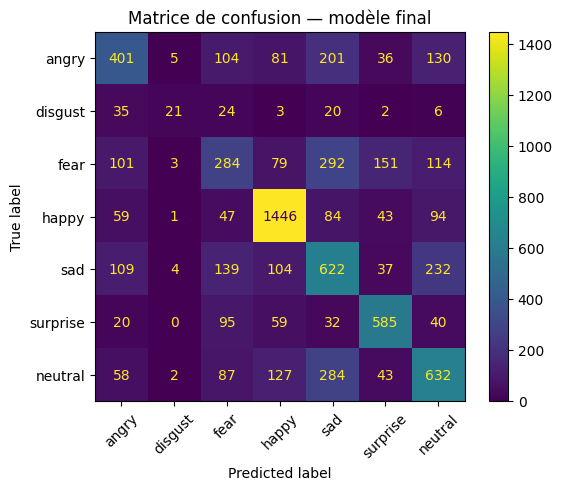

In [72]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

disp.plot(xticks_rotation=45)

plt.title("Matrice de confusion — modèle final")
plt.show()

In [73]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=classes
))

              precision    recall  f1-score   support

       angry       0.51      0.42      0.46       958
     disgust       0.58      0.19      0.29       111
        fear       0.36      0.28      0.31      1024
       happy       0.76      0.82      0.79      1774
         sad       0.41      0.50      0.45      1247
    surprise       0.65      0.70      0.68       831
     neutral       0.51      0.51      0.51      1233

    accuracy                           0.56      7178
   macro avg       0.54      0.49      0.50      7178
weighted avg       0.55      0.56      0.55      7178



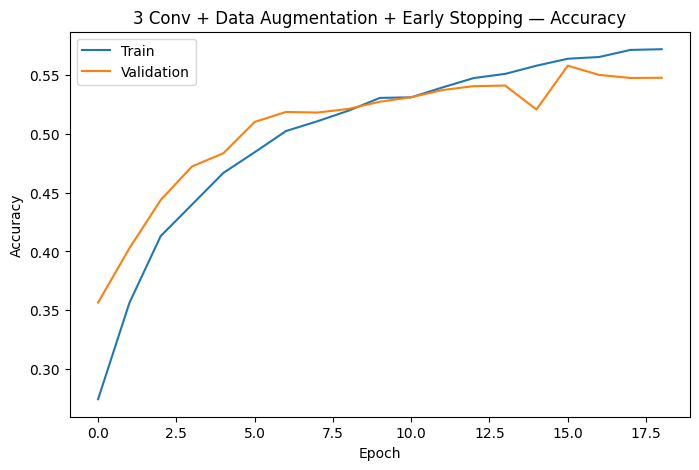

In [68]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_final.history["accuracy"],
    label="Train"
)

plt.plot(
    history_final.history["val_accuracy"],
    label="Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("3 Conv + Data Augmentation + Early Stopping — Accuracy")
plt.legend()
plt.show()

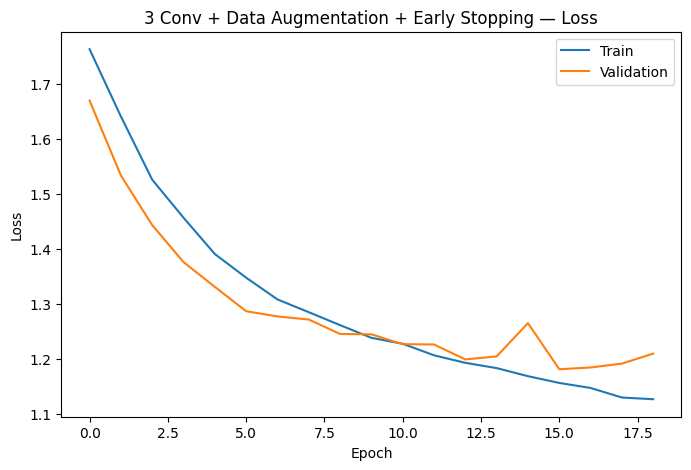

In [69]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_final.history["loss"],
    label="Train"
)

plt.plot(
    history_final.history["val_loss"],
    label="Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("3 Conv + Data Augmentation + Early Stopping — Loss")
plt.legend()
plt.show()

## Tableau récapitulatif des expériences

Les différentes expériences ont été réalisées en partant du même modèle CNN de référence et en modifiant progressivement certains éléments afin d'étudier leur influence sur les performances et la généralisation.

| Expérience | Modification principale | Meilleure validation accuracy | Observation |
|---|---|---:|---|
| CNN de référence | 2 blocs convolutionnels (32 → 64) | **51,31 %** | Fort surapprentissage |
| Expérience 1 | Ajout de Dropout | **52,68 %** | Réduction du surapprentissage |
| Expérience 2 | Data Augmentation | **53,29 %** | Meilleure généralisation et faible écart train/validation |
| Expérience 3 | Early Stopping | **52,28 %** | Arrêt avant que le surapprentissage ne devienne trop important |
| Expérience 4 | Ajout d'un 3ᵉ bloc convolutionnel (128 filtres) | **56,22 %** | Meilleure accuracy, mais fort surapprentissage |
| Expérience 5 | CNN + Batch Normalization + Dropout + Data Augmentation + Global Average Pooling | **54,81 %** | Architecture plus complexe, mais pas de gain par rapport aux meilleurs modèles |
| **Modèle final** | **3 blocs convolutionnels + Data Augmentation + Early Stopping** | **55,80 %** | **Bon compromis entre performance et généralisation** |

### Analyse des expériences

Le modèle CNN de référence atteint une meilleure accuracy de validation de **51,31 %**. Cependant, l'accuracy d'entraînement augmente fortement jusqu'à environ **98 %**, alors que l'accuracy de validation reste autour de 50 %. Cette différence importante montre un **surapprentissage important**.

L'**Expérience 1**, avec l'ajout du Dropout, améliore légèrement la meilleure accuracy de validation, qui atteint **52,68 %**. Le Dropout limite la dépendance du modèle à certains neurones et permet donc de réduire le surapprentissage.

L'**Expérience 2**, avec la Data Augmentation, atteint **53,29 %** de validation accuracy. L'écart entre l'entraînement et la validation reste faible, ce qui montre une meilleure capacité de généralisation. La Data Augmentation permet également de fournir au modèle des variations supplémentaires des images d'entraînement.

L'**Expérience 3**, avec Early Stopping, atteint **52,28 %** de validation accuracy. L'intérêt principal de cette expérience n'est pas d'obtenir la meilleure accuracy, mais de montrer qu'il est possible d'arrêter automatiquement l'entraînement lorsque la validation loss ne s'améliore plus. L'entraînement s'est arrêté après 9 époques au lieu des 20 prévues.

L'**Expérience 4** consiste à ajouter un troisième bloc convolutionnel avec **128 filtres**. Elle obtient la meilleure accuracy de validation parmi les expériences individuelles, avec **56,22 %**. Cependant, le modèle atteint environ **97 % d'accuracy sur l'entraînement**, tandis que la validation reste autour de 54–56 %. Cette différence montre un **fort surapprentissage**. Le gain de performance ne suffit donc pas à lui seul pour retenir ce modèle comme modèle final.

L'**Expérience 5** utilise une architecture plus avancée avec **Batch Normalization, Dropout, Data Augmentation et Global Average Pooling**. Elle atteint **54,81 %** de validation accuracy. Malgré une architecture plus complexe et une meilleure régularisation, elle ne dépasse pas le modèle obtenu avec trois blocs convolutionnels et Data Augmentation. Son temps d'entraînement est également beaucoup plus important.

### Choix du modèle final

Le modèle retenu est le modèle composé de :

**Data Augmentation → Conv2D(32) → MaxPooling → Conv2D(64) → MaxPooling → Conv2D(128) → MaxPooling → Flatten → Dense(128) → Softmax**

avec **Early Stopping** pendant l'entraînement.

Ce choix ne repose pas uniquement sur la valeur maximale de l'accuracy. L'Expérience 4 obtient effectivement une meilleure accuracy de validation de **56,22 %**, mais elle présente un surapprentissage beaucoup plus important.

Le modèle final atteint **55,80 % de validation accuracy**, avec environ **56,39 % d'accuracy sur l'entraînement** au meilleur point observé. L'écart entre les deux est donc très faible, environ **0,6 point de pourcentage**. Cela indique une meilleure généralisation.

La Data Augmentation permet de limiter le surapprentissage, tandis que l'ajout du troisième bloc convolutionnel augmente la capacité du réseau à apprendre des caractéristiques plus complexes. L'Early Stopping permet enfin d'arrêter l'entraînement lorsque la validation loss ne s'améliore plus et de conserver les meilleurs poids.

Le modèle final représente donc le **meilleur compromis entre performance, généralisation et complexité**.

### Pourquoi ne pas choisir uniquement le modèle avec la meilleure accuracy ?

L'objectif n'est pas simplement d'obtenir la plus grande accuracy sur les données de validation. Un modèle qui obtient une très bonne performance sur l'entraînement mais qui généralise mal risque de moins bien fonctionner sur de nouvelles images.

Par exemple, l'Expérience 4 atteint **56,22 %** de validation accuracy, mais son accuracy d'entraînement atteint environ **97 %**. Le modèle apprend donc très bien les données d'entraînement, sans obtenir une amélioration équivalente sur les données de validation.

À l'inverse, le modèle final atteint environ **56 % sur l'entraînement et 56 % sur la validation**. Même si son accuracy maximale est légèrement inférieure, son comportement indique une meilleure généralisation.


### Partie 8 — Détection de plusieurs visages et reconnaissance des expressions

**Objectif :** développer une application capable de détecter plusieurs visages dans une image et de prédire l’expression faciale de chaque personne.

Le système combine deux modèles complémentaires :

1. **YOLO Face :** détecte les visages dans l’image et fournit leurs coordonnées sous forme de boîtes englobantes (*bounding boxes*).
2. **CNN entraîné précédemment :** chaque visage détecté est extrait, converti en niveaux de gris, redimensionné en 48 × 48 pixels et normalisé. Notre modèle `model_final` prédit ensuite une des sept expressions : angry, disgust, fear, happy, sad, surprise ou neutral.

Les prédictions sont affichées directement sur l’image avec une boîte autour de chaque visage, le nom de l’expression et le niveau de confiance associé à cette prédiction.

**Limites :** la qualité du résultat dépend de la détection des visages, de leur visibilité et des performances du CNN. Le niveau de confiance est celui du classifieur et ne garantit pas que l’expression prédite soit correcte.

In [74]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 60.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 7.9 MB/s eta 0:00:00


In [75]:
from ultralytics import YOLO
import os

# Télécharger un modèle YOLO pré-entraîné spécifiquement
# pour détecter les visages
weights_path = "yolov8n-face.pt"

if not os.path.exists(weights_path):
    !wget -q https://github.com/akanametov/yolo-face/releases/download/1.0.0/yolov8n-face.pt -O yolov8n-face.pt

face_detector = YOLO(weights_path)

print("Détecteur YOLO Face chargé.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Détecteur YOLO Face chargé.


Saving An-example-of-all-six-facial-expressions-from-the-top-left-picture-Happy-Sad-Angry.webp to An-example-of-all-six-facial-expressions-from-the-top-left-picture-Happy-Sad-Angry.webp


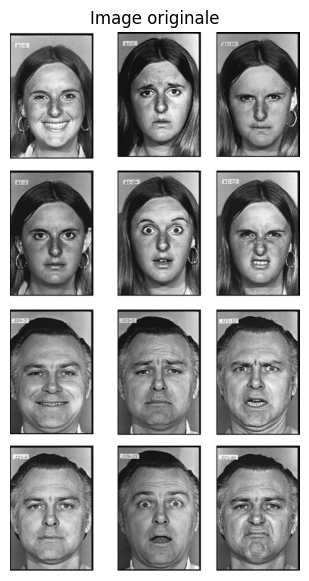

In [76]:
from google.colab import files
from PIL import Image
import numpy as np
import cv2
import matplotlib.pyplot as plt

uploaded = files.upload()

image_path = next(iter(uploaded.keys()))

image_bgr = cv2.imread(image_path)

if image_bgr is None:
    raise ValueError("Impossible de lire l'image importée.")

image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 7))
plt.imshow(image_rgb)
plt.title("Image originale")
plt.axis("off")
plt.show()

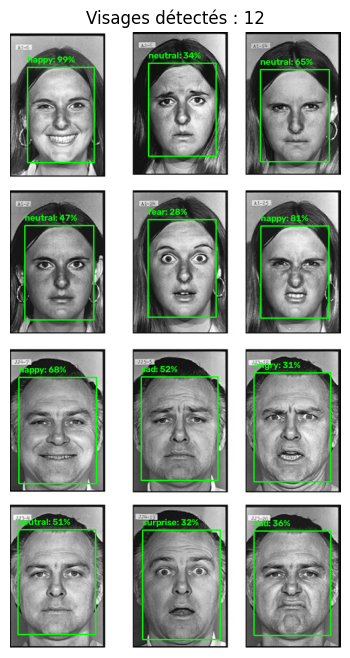

Nombre de visages détectés : 12


In [77]:
# Copie de l'image pour dessiner les résultats
result_image = image_bgr.copy()

# Détection des visages
results = face_detector.predict(
    source=image_bgr,
    conf=0.25,
    verbose=False
)

face_count = 0

for result in results:
    if result.boxes is None:
        continue

    for box in result.boxes:
        # Coordonnées de la boîte englobante
        x1, y1, x2, y2 = map(
            int, box.xyxy[0].cpu().numpy()
        )

        # S'assurer que les coordonnées restent dans l'image
        h, w = image_bgr.shape[:2]
        x1, x2 = max(0, x1), min(w, x2)
        y1, y2 = max(0, y1), min(h, y2)

        # Extraire le visage
        face = image_bgr[y1:y2, x1:x2]

        if face.size == 0:
            continue

        # Prétraitement compatible avec le CNN FER2013
        face_gray = cv2.cvtColor(face, cv2.COLOR_BGR2GRAY)
        face_resized = cv2.resize(face_gray, (48, 48))
        face_normalized = face_resized.astype("float32") / 255.0

        # Ajouter les dimensions canal et batch
        face_input = face_normalized[np.newaxis, ..., np.newaxis]

        # Prédire l'expression
        probabilities = model_final.predict(
            face_input, verbose=0
        )[0]

        predicted_index = int(np.argmax(probabilities))
        expression = classes[predicted_index]
        confidence = float(probabilities[predicted_index])

        # Afficher la boîte et la prédiction
        label = f"{expression}: {confidence:.0%}"

        cv2.rectangle(
            result_image,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

        text_y = max(25, y1 - 10)

        cv2.putText(
            result_image,
            label,
            (x1, text_y),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.65,
            (0, 255, 0),
            2
        )

        face_count += 1

# Afficher l'image annotée
result_rgb = cv2.cvtColor(result_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 8))
plt.imshow(result_rgb)
plt.title(f"Visages détectés : {face_count}")
plt.axis("off")
plt.show()

print(f"Nombre de visages détectés : {face_count}")

### Partie 9 — Extension vidéo

**Objectif :** étendre le système précédent à une vidéo afin de détecter les visages et de suivre les expressions prédites au fil des images (*frames*).

Le traitement suit les étapes suivantes :

1. Lire la vidéo image par image avec OpenCV.
2. Détecter les visages dans chaque image à l'aide de YOLO Face.
3. Extraire et prétraiter chaque visage détecté.
4. Utiliser le CNN pour prédire l'expression faciale.
5. Dessiner les boîtes englobantes et les prédictions sur chaque image.
6. Enregistrer les images annotées dans une nouvelle vidéo.

Cette extension montre comment intégrer un détecteur d'objets et un classifieur d'images dans un même pipeline. Le système effectue une prédiction par visage et par image : il ne garantit donc pas un suivi persistant de chaque personne entre les images.

Cette partie constitue une extension expérimentale du projet. Les performances dépendent notamment de la vitesse de traitement, de la qualité de la vidéo et des limites du modèle de reconnaissance des expressions.

In [78]:
from google.colab import files
import cv2
import os
from IPython.display import display, Video

uploaded_video = files.upload()

video_path = next(iter(uploaded_video.keys()))

print("Vidéo importée :", video_path)

Saving 129420-744370583.mp4 to 129420-744370583.mp4
Vidéo importée : 129420-744370583.mp4


In [80]:
# Ouvrir la vidéo
cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise ValueError("Impossible d'ouvrir la vidéo.")

# Informations sur la vidéo
fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

if fps <= 0:
    fps = 25.0

# Fichier de sortie
output_path = "video_expressions_yolo.mp4"

fourcc = cv2.VideoWriter_fourcc(*"mp4v")
writer = cv2.VideoWriter(
    output_path,
    fourcc,
    fps,
    (width, height)
)

frame_count = 0

while True:
    ret, frame = cap.read()

    if not ret:
        break

    # Détecter les visages dans l'image courante
    results = face_detector.predict(
        source=frame,
        conf=0.25,
        verbose=False
    )

    for result in results:
        if result.boxes is None:
            continue

        for box in result.boxes:
            x1, y1, x2, y2 = map(
                int, box.xyxy[0].cpu().numpy()
            )

            # Limiter les coordonnées aux dimensions de l'image
            x1, x2 = max(0, x1), min(width, x2)
            y1, y2 = max(0, y1), min(height, y2)

            face = frame[y1:y2, x1:x2]

            if face.size == 0:
                continue

            # Prétraitement du visage
            face_gray = cv2.cvtColor(
                face, cv2.COLOR_BGR2GRAY
            )
            face_resized = cv2.resize(
                face_gray, (48, 48)
            )
            face_normalized = (
                face_resized.astype("float32") / 255.0
            )

            face_input = face_normalized[
                np.newaxis, ..., np.newaxis
            ]

            # Classification de l'expression
            probabilities = model_final.predict(
                face_input, verbose=0
            )[0]

            predicted_index = int(
                np.argmax(probabilities)
            )

            expression = classes[predicted_index]
            confidence = float(
                probabilities[predicted_index]
            )

            label = f"{expression}: {confidence:.0%}"

            # Dessiner la boîte et le label
            cv2.rectangle(
                frame,
                (x1, y1),
                (x2, y2),
                (0, 255, 0),
                2
            )

            cv2.putText(
                frame,
                label,
                (x1, max(25, y1 - 10)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.65,
                (0, 255, 0),
                2
            )

    # Enregistrer l'image annotée
    writer.write(frame)
    frame_count += 1

    if frame_count % 100 == 0:
        print(f"{frame_count} images traitées")

# Libérer les ressources
cap.release()
writer.release()

print("Traitement terminé.")
print("Nombre d'images traitées :", frame_count)
print("Vidéo de sortie :", output_path)

100 images traitées
Traitement terminé.
Nombre d'images traitées : 197
Vidéo de sortie : video_expressions_yolo.mp4


In [82]:
if os.path.exists(output_path) and os.path.getsize(output_path) > 0:
    display(Video(output_path, embed=True, width=720))
else:
    print("La vidéo de sortie n'a pas pu être créée.")

In [83]:
!ffmpeg -y -i video_expressions_yolo.mp4 \
    -c:v libx264 -pix_fmt yuv420p \
    -movflags +faststart \
    video_expressions_yolo_fixed.mp4

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

In [84]:
from IPython.display import Video, display
import os

video_fixed = "video_expressions_yolo_fixed.mp4"

if os.path.exists(video_fixed) and os.path.getsize(video_fixed) > 0:
    display(Video(video_fixed, embed=True, width=720))
else:
    print("La conversion a échoué.")